# Correctness while learning libraries

Training raises library use, and pass@1 stays about the same (table 1). This notebook asks what happens underneath, for Qwen3-8B and OLMo-3-7B-Think at each run's final epoch (epoch 4), on LibReuseBench test with the plain prompt:

1. Does the model solve the **same problems** after training as before?
2. Are the problems that **switch to a library** more likely to be right?
3. Does the model take problems it **already knew how to solve** and just solve them with a library?

**The method, in one paragraph.** Each of the 216 tasks has 5 sampled answers. A task is **solved** if at least 3 of its 5 answers pass, and **uses a library** if at least 3 of them import and use a third-party library. Each task is labelled twice, for the base model and for the trained model, and then sorted into one of four outcomes:

| Outcome | Before training | After training |
|---|---|---|
| **Kept** | solved | solved |
| **Newly solved** | not solved | solved |
| **Lost** | solved | not solved |
| **Failed both** | not solved | not solved |

The tasks are split into those that **switched to a library** (base model by hand, trained model with a library) and those that **stayed hand-written** (by hand both times). The stayed-hand-written tasks are the reference. With 5 answers per task, a task near the 3-of-5 line can flip by chance, so these tasks show how much churn to expect without a library. A third, small group used a library both before and after; it is shown in the table but isn't needed for the questions.

In [1]:
"""Compare each LibReuseBench test task's outcome before and after training, by whether it switched to a library."""

import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from llm_cgr import load_jsonl

from src.utils.paths import baseline_dir, training_run_dir


# run from the repo root (the folder holding .git), so the relative paths src uses
# (config/, output/) resolve - this notebook lives beside its results, in output/
REPO_ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / ".git").exists()
)
os.chdir(REPO_ROOT)

# the models, runs and epoch are the same as in paper_figures.ipynb
MODELS = {
    "qwen3-8b": "Qwen3-8B",
    "olmo3-7b": "OLMo-3-7B-Think",
}
REWARDS = ["import", "usage", "target"]
RUNS = {
    "qwen3-8b": {
        "import": "qwen3-8b-f2ca",
        "usage": "qwen3-8b-3079",
        "target": "qwen3-8b-f57b",
    },
    "olmo3-7b": {
        "import": "olmo3-7b-e93f",
        "usage": "olmo3-7b-cb85",
        "target": "olmo3-7b-15e4",
    },
}
FINAL_EPOCH = 4
RESULTS_FILE = "libreusebench_test-default_16k-base.generations.jsonl"
TEST_TASKS = 216

# a task is solved, or uses a library, when at least 3 of its 5 answers do
MAJORITY = 0.5
GROUPS = ["Switched to a library", "Stayed hand-written", "Library before and after"]
OUTCOMES = ["Newly solved", "Kept", "Lost", "Failed both"]
OUTPUT_DIR = Path("output") / "figures"

## Label every task

For each model (base or trained run), each task gets three yes/no labels: solved, uses a library, and **mostly cut off** (at least 3 of 5 answers ran out of tokens). The last one matters for OLMo-3-7B-Think, whose base model runs out of tokens on 22% of its answers. Its trained runs do so on only 4-5%, so some tasks are newly solved just because the model now finishes its answer.

In [2]:
def load_task_labels(
    model: str,
    reward: str | None,
) -> pd.DataFrame:
    """
    Load the LibReuseBench test answers of the base model (no reward) or of one run's
    final checkpoint, and label each task from its 5 answers.

    Returns one row per task: solved, uses a library, and mostly cut off (all yes/no).
    """
    if reward is None:
        folder = baseline_dir(model)
    else:
        run_dir = training_run_dir(
            base_model=model,
            run_id=RUNS[model][reward],
        )
        folder = run_dir / f"epoch{FINAL_EPOCH}"
    answers = pd.DataFrame(load_jsonl(file_path=str(folder / RESULTS_FILE)))
    answers["cut_off"] = answers["stop_reason"] != "eos"
    by_task = answers.groupby("task_id")
    return pd.DataFrame(
        {
            "solved": by_task["passed"].mean() >= MAJORITY,
            "library": by_task["external_lib_used"].mean() >= MAJORITY,
            "cut_off": by_task["cut_off"].mean() >= MAJORITY,
        }
    )


def compare_tasks(
    model: str,
    reward: str,
) -> pd.DataFrame:
    """
    Put the base model's and one trained run's labels side by side, and give each task
    its group (did it switch to a library?) and its outcome (see the table at the top).

    Returns one row per task.
    """
    before = load_task_labels(model=model, reward=None)
    after = load_task_labels(model=model, reward=reward)
    tasks = before.join(after, lsuffix="_before", rsuffix="_after")
    assert len(tasks) == TEST_TASKS, f"{model} {reward}: {len(tasks)} tasks"

    # the group: library use before and after training
    tasks["group"] = None
    tasks.loc[~tasks["library_before"] & tasks["library_after"], "group"] = GROUPS[0]
    tasks.loc[~tasks["library_before"] & ~tasks["library_after"], "group"] = GROUPS[1]
    tasks.loc[tasks["library_before"] & tasks["library_after"], "group"] = GROUPS[2]
    # no task stops using a library in these runs, so every task has a group
    assert tasks["group"].notna().all(), f"{model} {reward}: a task dropped its library"

    # the outcome: solved before and after training
    solved_before = tasks["solved_before"]
    solved_after = tasks["solved_after"]
    tasks.loc[~solved_before & solved_after, "outcome"] = "Newly solved"
    tasks.loc[solved_before & solved_after, "outcome"] = "Kept"
    tasks.loc[solved_before & ~solved_after, "outcome"] = "Lost"
    tasks.loc[~solved_before & ~solved_after, "outcome"] = "Failed both"
    return tasks


# every task of every run, in one table
all_tasks = pd.concat(
    [
        compare_tasks(model=model, reward=reward).assign(
            model=MODELS[model],
            reward=reward,
        )
        for model in MODELS
        for reward in REWARDS
    ]
)

## What happened to each task

One row per run and group. The columns count tasks:

- **tasks**: how many tasks are in the group;
- **solved before / solved after**: how many the base model and the trained run solve;
- **newly solved / kept / lost / failed both**: the four outcomes (they add up to *tasks*);
- **newly solved, base cut off**: of the newly solved tasks, how many the base model mostly ran out of tokens on. These are gains from finishing the answer, whatever the library.

In [3]:
rows = []
for model in MODELS.values():
    for reward in REWARDS:
        for group in GROUPS:
            tasks = all_tasks[
                (all_tasks["model"] == model)
                & (all_tasks["reward"] == reward)
                & (all_tasks["group"] == group)
            ]
            outcome_counts = tasks["outcome"].value_counts()
            newly_solved = tasks[tasks["outcome"] == "Newly solved"]
            rows.append(
                {
                    "model": model,
                    "reward": reward,
                    "group": group,
                    "tasks": len(tasks),
                    "solved before": tasks["solved_before"].sum(),
                    "solved after": tasks["solved_after"].sum(),
                    **{outcome: outcome_counts.get(outcome, 0) for outcome in OUTCOMES},
                    "newly solved, base cut off": newly_solved["cut_off_before"].sum(),
                }
            )
outcome_table = pd.DataFrame(rows).set_index(["model", "reward", "group"])
display(outcome_table)

tasks  solved before  \
model           reward group                                            
Qwen3-8B        import Switched to a library        47             34   
                       Stayed hand-written         134            105   
                       Library before and after     35             29   
                usage  Switched to a library        39             27   
                       Stayed hand-written         142            112   
                       Library before and after     35             29   
                target Switched to a library        53             40   
                       Stayed hand-written         128             99   
                       Library before and after     35             29   
OLMo-3-7B-Think import Switched to a library        73             35   
                       Stayed hand-written         139             98   
                       Library before and after      4              3   
                usage  Switched to a library        53             22   
                       Stayed hand-written         159            111   
                       Library before and after      4              3   
                target Switched to a library        48             17   
                       Stayed hand-written         164            116   
                       Library before and after      4              3   

                                                 solved after  Newly solved  \
model           reward group                                                  
Qwen3-8B        import Switched to a library               37            11   
                       Stayed hand-written                110             8   
                       Library before and after            29             2   
                usage  Switched to a library               31             9   
                       Stayed hand-written                116             8   
                       Library before and after            27             1   
                target Switched to a library               43            12   
                       Stayed hand-written                104             8   
                       Library before and after            29             1   
OLMo-3-7B-Think import Switched to a library               36            16   
                       Stayed hand-written                100            11   
                       Library before and after             4             1   
                usage  Switched to a library               34            21   
                       Stayed hand-written                111             8   
                       Library before and after             4             1   
                target Switched to a library               28            17   
                       Stayed hand-written                119            12   
                       Library before and after             2             0   

                                                 Kept  Lost  Failed both  \
model           reward group                                               
Qwen3-8B        import Switched to a library       26     8            2   
                       Stayed hand-written        102     3           21   
                       Library before and after    27     2            4   
                usage  Switched to a library       22     5            3   
                       Stayed hand-written        108     4           22   
                       Library before and after    26     3            5   
                target Switched to a library       31     9            1   
                       Stayed hand-written         96     3           21   
                       Library before and after    28     1            5   
OLMo-3-7B-Think import Switched to a library       20    15           22   
                       Stayed hand-written         89     9           30   
                   

## Figure: what happened to the tasks that switched to a library

One panel per model. Each bar is split into the four outcomes, as a share of the tasks in that group, with the three runs (rewards) together; the table above gives each run, and the three look alike. Read the bars in two halves:

- **left two segments** (newly solved + kept): solved after training;
- **middle two segments** (kept + lost): solved before training.

The *stayed hand-written* bar is the reference: it shows how much tasks move between runs without a library.

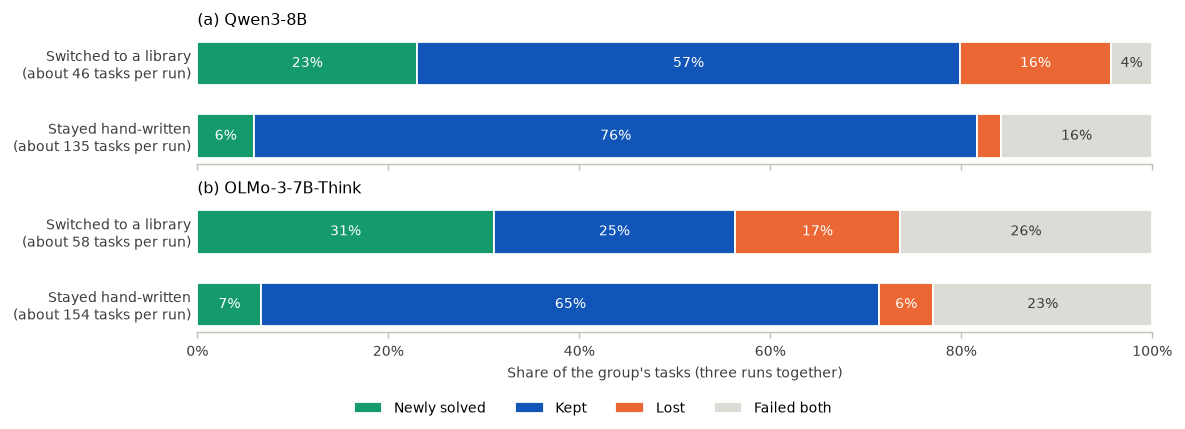

In [4]:
# the paper's text and axis colours, from paper_figures.ipynb
INK = "#3d3d3a"
RULE = "#c3c2b7"
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": RULE,
        "axes.labelcolor": INK,
        "axes.titlesize": 9,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "xtick.color": RULE,
        "xtick.labelcolor": INK,
        "ytick.labelcolor": INK,
        "ytick.major.size": 0,
        "font.size": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
    }
)
# green for gains and orange for losses, with blue (kept) between them, so the two
# stay apart for colour-blind readers (checked with a palette validator); failed both
# is a neutral grey
OUTCOME_COLOURS = {
    "Newly solved": "#159a6b",
    "Kept": "#1155b9",
    "Lost": "#eb6834",
    "Failed both": "#dcdbd5",
}
# white labels on the dark segments, ink on the grey one
LABEL_COLOURS = {
    "Newly solved": "white",
    "Kept": "white",
    "Lost": "white",
    "Failed both": INK,
}
FIGURE_GROUPS = GROUPS[:2]

fig, axes = plt.subplots(
    len(MODELS),
    1,
    figsize=(9.0, 3.2),
    layout="constrained",
    sharex=True,
)
for ax, (letter, name) in zip(axes, zip("ab", MODELS.values())):
    model_tasks = all_tasks[all_tasks["model"] == name]
    # top bar first: switched to a library
    for position, group in enumerate(reversed(FIGURE_GROUPS)):
        tasks = model_tasks[model_tasks["group"] == group]
        shares = tasks["outcome"].value_counts(normalize=True)
        left = 0.0
        for outcome in OUTCOMES:
            share = shares.get(outcome, 0.0)
            ax.barh(
                position,
                share,
                left=left,
                height=0.6,
                color=OUTCOME_COLOURS[outcome],
                edgecolor="white",
                linewidth=1,
                label=outcome if position == 0 else None,
            )
            # label segments wide enough to hold the number
            if share >= 0.04:
                ax.text(
                    left + share / 2,
                    position,
                    f"{share:.0%}",
                    ha="center",
                    va="center",
                    color=LABEL_COLOURS[outcome],
                    fontsize=7.5,
                )
            left += share
    tasks_per_run = {
        group: (model_tasks["group"] == group).sum() / len(REWARDS)
        for group in FIGURE_GROUPS
    }
    ax.set_yticks(
        range(len(FIGURE_GROUPS)),
        labels=[
            f"{group}\n(about {tasks_per_run[group]:.0f} tasks per run)"
            for group in reversed(FIGURE_GROUPS)
        ],
    )
    ax.set_title(f"({letter}) {name}")
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
axes[-1].set_xlabel("Share of the group's tasks (three runs together)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="outside lower center",
    ncols=len(OUTCOMES),
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    OUTPUT_DIR / "correctness_by_task.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# the figure's numbers, as a table
display(
    all_tasks[all_tasks["group"].isin(FIGURE_GROUPS)]
    .groupby(["model", "group"], sort=False)["outcome"]
    .value_counts(normalize=True)
    .unstack()[OUTCOMES]
    .style.format("{:.0%}")
)

## Answers

The percentages are from the figure (the three runs together); the table above gives each run.

**1. Same problems?** Mostly, yes. Tasks that stay hand-written barely move: 76% are kept by Qwen3-8B and 65% by OLMo-3-7B-Think, with only 6-7% newly solved and 2-6% lost. That is the background churn from sampling. Almost all of the change is in the tasks that switch to a library.

**2. Are the switched tasks more likely to be right?**

- **Qwen3-8B: about the same.** Solved switched tasks go from 73% (kept + lost) to 80% (newly solved + kept). The stayed-hand-written tasks go from 78% to 82%, so the rise is about the same. The switch does shake the results up: 22% of the switched tasks the base model solved are lost, but 84% of the ones it failed are fixed. These roughly cancel out.
- **OLMo-3-7B-Think: higher, but not because of the library.** Solved switched tasks go from 42% to 56%. But about half of the newly solved ones (26 of 54, the three runs together) are tasks where the base model mostly ran out of tokens. Leave those out and the newly solved switched tasks (28) about equal the lost ones (30).

**3. Known, then done with a library?**

- **Qwen3-8B: yes.** 73% of its switched tasks were already solved by hand, and about 4 in 5 of those are still solved with a library. Training mostly moves problems it already knows how to solve over to a library.
- **OLMo-3-7B-Think: less so, and at a cost.** Only 42% of its switched tasks were solved before, and about 4 in 10 of those are lost after the switch, against about 1 in 12 of the tasks that stay hand-written. When OLMo moves a problem it knew over to a library, it often gets it wrong.

**Caveat.** With 5 answers per task, a task near the 3-of-5 line can flip by chance. The stayed-hand-written tasks show how much that happens, which is why they are the reference.